Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [1]:
import os
import sys
import json
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor


The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [2]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [3]:
#Excel File Import
csv_file = 'Silicon_Dataset.csv'
df = pd.read_csv(csv_file)
df = df.apply(pd.to_numeric)

print(df.head())

    Lg  Lch    Tox          Nsub         PeakV  Vds       Vgs            Id
0  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -1.000000  3.220000e-16
1  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.974747  3.220000e-16
2  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.949495  3.210000e-16
3  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.924242  3.230000e-16
4  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.898990  3.230000e-16


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [4]:

# Assuming 'df' is your DataFrame and 'Id' is the target column
input_columns = ['Lg', 'Lch', 'Tox', 'Nsub', 'PeakV', 'Vds', 'Vgs']
output_column = 'Id'

# Prepare the data
X = df[input_columns].values
Y = df[output_column].values

# Take the logarithm base 10 of the output data
Y = np.log10(Y)

print(Y)

[-15.49214413 -15.49214413 -15.49349497 ... -13.91721463 -13.91364017
 -13.91364017]


This section of code mainly used do feature selection and show the importance of each different feature's relationship and importance between the factors.

In [5]:
# # Splitting the data into train and test sets
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# # Train a Random Forest Regressor model
# rf_model = RandomForestRegressor(random_state=42)
# rf_model.fit(X_train, Y_train)

# # Compute the baseline Mean Squared Error
# Y_pred = rf_model.predict(X_test)
# baseline_mse = mean_squared_error(Y_test, Y_pred)
# print(f"Baseline Mean Squared Error: {baseline_mse:.4f}")

# # Get feature importances
# feature_importances = rf_model.feature_importances_

# # Display feature importance
# feature_names = X_test.columns.tolist()
# importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
# importance_df = importance_df.sort_values(by='Importance', ascending=False)

# print(importance_df)

# # Plot feature importance
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'])
# plt.xlabel('Importance')
# plt.ylabel('Feature')
# plt.title('Feature Importance')
# plt.gca().invert_yaxis()
# plt.show()

This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [6]:

# Data Sampling: Pick the first 10000 samples
sample_num = 10000
X = X[:sample_num]
Y = Y[:sample_num]
 
# Normalize the data
scaler_X = StandardScaler()
scaler_Y = StandardScaler()
X = scaler_X.fit_transform(X)
Y = scaler_Y.fit_transform(Y.reshape(-1, 1)).flatten()

# Here print the input and output separately
print(X)
print(Y)



[[-1.38777878e-17 -1.22474487e+00 -1.28373482e+00 ...  1.00000000e+00
  -2.77555756e-17 -1.71481604e+00]
 [-1.38777878e-17 -1.22474487e+00 -1.28373482e+00 ...  1.00000000e+00
  -2.77555756e-17 -1.68017329e+00]
 [-1.38777878e-17 -1.22474487e+00 -1.28373482e+00 ...  1.00000000e+00
  -2.77555756e-17 -1.64553055e+00]
 ...
 [-1.38777878e-17  1.83711731e+00 -5.86052851e-01 ... -1.00000000e+00
  -2.77555756e-17  1.64553055e+00]
 [-1.38777878e-17  1.83711731e+00 -5.86052851e-01 ... -1.00000000e+00
  -2.77555756e-17  1.68017329e+00]
 [-1.38777878e-17  1.83711731e+00 -5.86052851e-01 ... -1.00000000e+00
  -2.77555756e-17  1.71481604e+00]]
[-1.0269995  -1.0269995  -1.0273331  ...  1.67910757  1.68992942
  1.70066385]


# Random Forest Learning

The code below utilized random forest model to complete such a task. The random forest will generate a first step result based on the dataset, but the more accurate data should be trained using the other model like GCN.

In [7]:
# Split the data into training and testing sets without randomization
split_index = int(0.8 * sample_num)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = Y[:split_index], Y[split_index:]

# Define the XGBoost model
xgb_model = XGBRegressor(random_state=42)

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Perform Grid Search with cross-validation
grid_search = GridSearchCV(estimator=xgb_model, param_grid=param_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=2)
grid_search.fit(X_train, y_train)

# Get the best model from grid search
best_xgb_model = grid_search.best_estimator_

# Calculate the number of parameters in the XGBoost model
booster = best_xgb_model.get_booster()
model_dump = booster.get_dump()
num_trees = len(model_dump)  # Number of trees in the model
print(f'Number of trees: {num_trees}')

# Predict on the validation set
y_pred = best_xgb_model.predict(X_test)
val_mse = mean_absolute_error(y_test, y_pred)
print(f'Best Validation MSE: {val_mse:.6f}')

# Print the best parameters
print(f'Best Parameters: {grid_search.best_params_}')

Fitting 5 folds for each of 108 candidates, totalling 540 fits


Number of trees: 300
Best Validation MSE: 0.006866
Best Parameters: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}


# Visualization
Visualize the required ID VG diagram using the visualization tool.

<Figure size 800x1800 with 0 Axes>

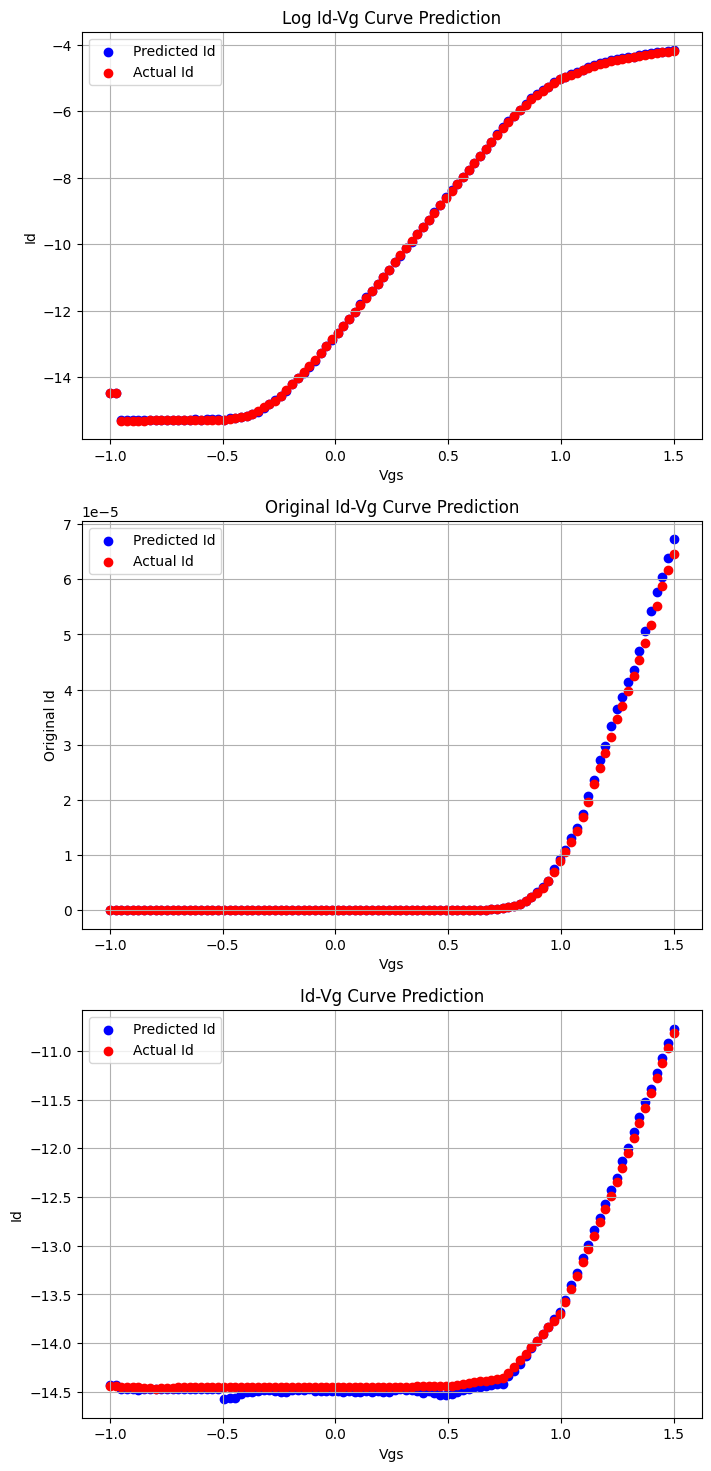

In [8]:
# Reverse the normalization process for the predictions and the actual values
y_test_original = scaler_Y.inverse_transform(y_test.reshape(-1, 1)).flatten()
y_pred_original = scaler_Y.inverse_transform(y_pred.reshape(-1, 1)).flatten()

# Generate Id-Vg diagram
Vgs_index = input_columns.index('Vgs')  # Get the index of the Vgs column
Vgs_test = scaler_X.inverse_transform(X_test)[:, Vgs_index]  # Extract the Vgs values from the test set

# Plot the real and predicted Id-Vg curves
plt.figure(figsize=(8, 18))

# Take the logarithm of the output data for the second subplot
y_test_exp = np.power(10,y_test_original)
y_pred_exp = np.power(10,y_pred_original)


# Plot the real and predicted Id-Vg curves
plt.figure(figsize=(8, 18))

# The difference of these three pictures are mainly different process parameters
plt.subplot(3, 1, 1)   # 3 rows and 1 column, 1st sub-picture
plt.scatter(Vgs_test[502:602], y_pred_original[502:602], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[502:602], y_test_original[502:602], label='Actual Id', color='red', linewidth=1)

plt.xlabel('Vgs')
plt.ylabel('Id')
plt.title('Log Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 2) # 3 rows and 1 column, 2nd sub-picture
plt.scatter(Vgs_test[502:602], y_pred_exp[502:602], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[502:602], y_test_exp[502:602], label='Actual Id', color='red', linewidth=1)
plt.xlabel('Vgs')
plt.ylabel('Original Id')
plt.title('Original Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.subplot(3, 1, 3) # 3 rows and 1 column, 3rd sub-picture
plt.scatter(Vgs_test[602:702], y_pred_original[602:702], label='Predicted Id', color='blue', linewidth=1)
plt.scatter(Vgs_test[602:702], y_test_original[602:702], label='Actual Id', color='red', linewidth=1)
plt.xlabel('Vgs')
plt.ylabel('Id')
plt.title('Id-Vg Curve Prediction')
plt.legend()
plt.grid(True)

plt.show()